# ===============================
# 01_EDA_FeatureEngineering.ipynb
# ===============================

Train shape: (1017209, 9), Store shape: (1115, 10)
Combined dataset shape: (1017209, 18)
               Store      DayOfWeek                           Date  \
count  844338.000000  844338.000000                         844338   
mean      558.421374       3.520350  2014-04-11 01:08:38.729702912   
min         1.000000       1.000000            2013-01-01 00:00:00   
25%       280.000000       2.000000            2013-08-16 00:00:00   
50%       558.000000       3.000000            2014-03-31 00:00:00   
75%       837.000000       5.000000            2014-12-11 00:00:00   
max      1115.000000       7.000000            2015-07-31 00:00:00   
std       321.730861       1.723712                            NaN   

               Sales      Customers      Open          Promo  SchoolHoliday  \
count  844338.000000  844338.000000  844338.0  844338.000000  844338.000000   
mean     6955.959134     762.777166       1.0       0.446356       0.193578   
min        46.000000       8.000000       1

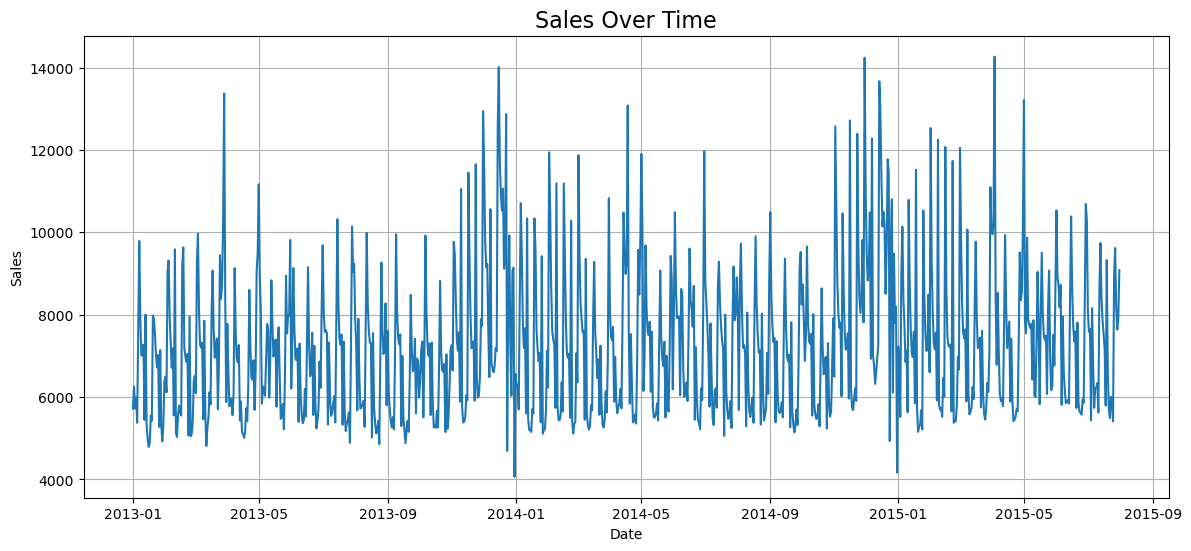

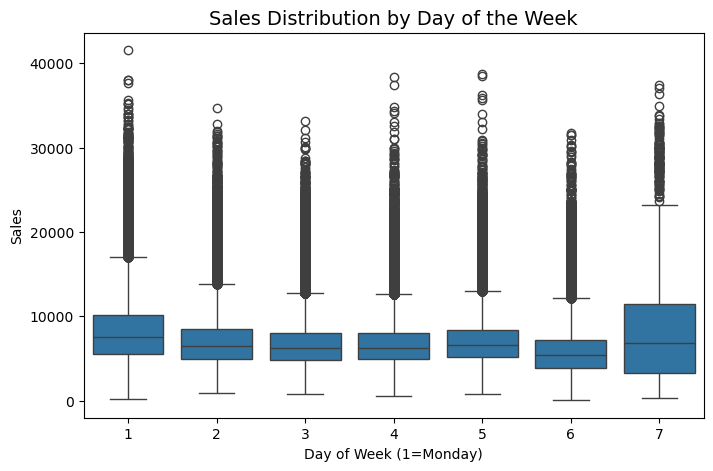

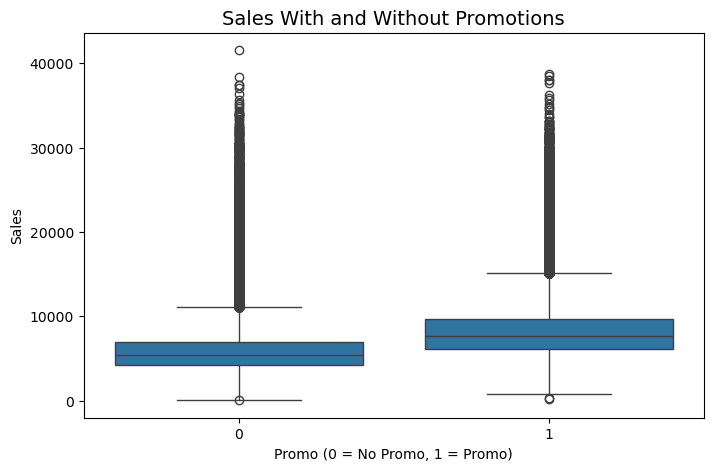

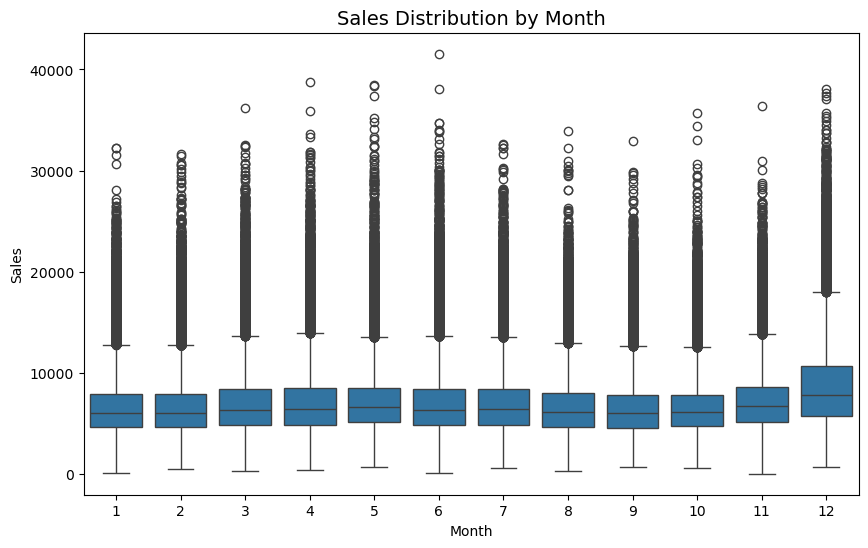

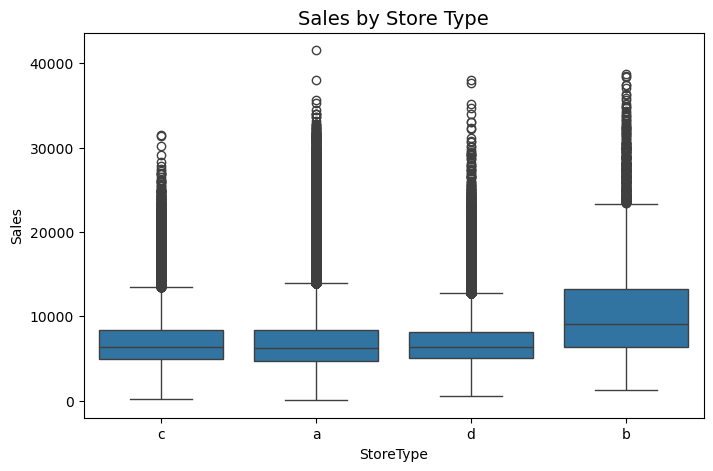

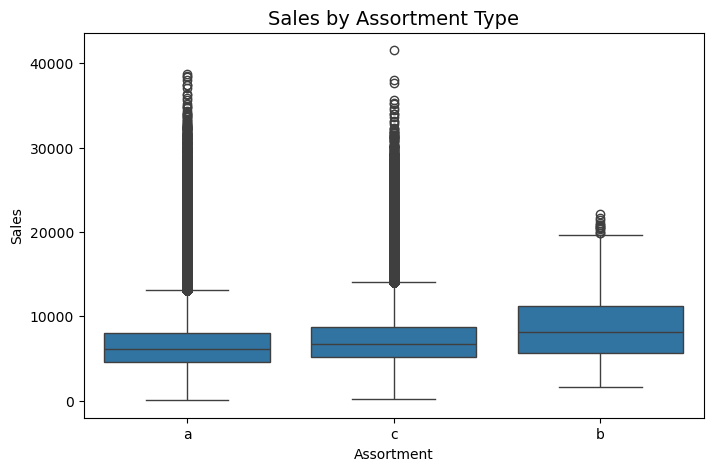

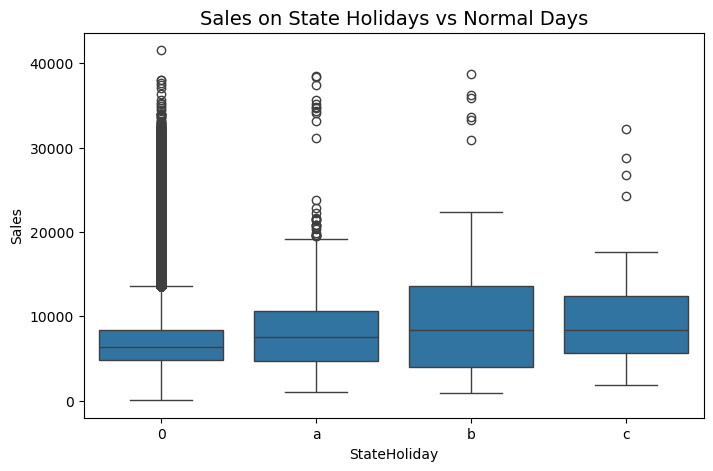

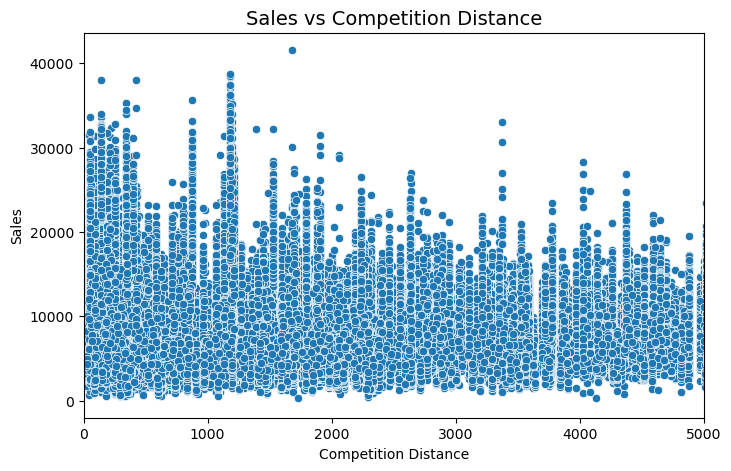

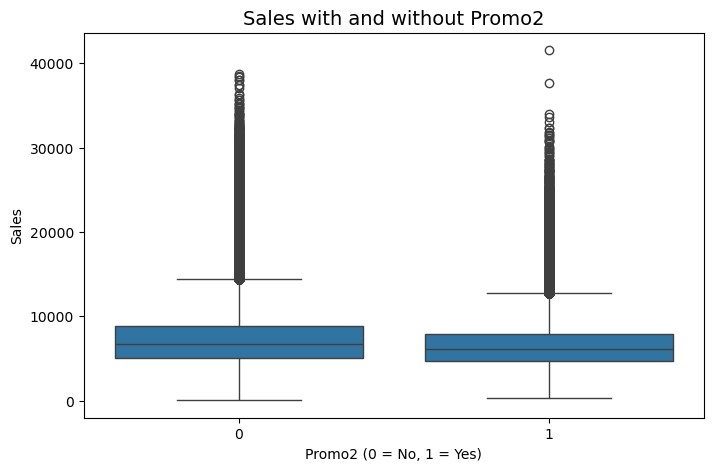

Saved cleaned data to data/cleaned_rossmann.csv 🚀


In [3]:


# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 2. Load Data
train = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/train.csv')
store = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/store.csv')
print(f"Train shape: {train.shape}, Store shape: {store.shape}")

# 3. Merge Data
df = pd.merge(train, store, how='left', on='Store')
print(f"Combined dataset shape: {df.shape}")

# 4. Parse Dates
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week

# 5. Data Cleaning
# Remove rows where store was closed
df = df[df['Open'] == 1]
# Remove rows with 0 sales
df = df[df['Sales'] > 0]

# 6. Quick Overview
print(df.describe())

# 7. Missing Values Check
print("\nMissing values per column:\n", df.isnull().sum())

# 8. Basic Sales Trends

## Sales Over Time
plt.figure(figsize=(14,6))
sns.lineplot(x='Date', y='Sales', data=df, ci=None)
plt.title('Sales Over Time', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Sales')
plt.grid(True)
plt.show()

## Sales by Day of Week
plt.figure(figsize=(8,5))
sns.boxplot(x='DayOfWeek', y='Sales', data=df)
plt.title('Sales Distribution by Day of the Week', fontsize=14)
plt.xlabel('Day of Week (1=Monday)')
plt.ylabel('Sales')
plt.show()

## Sales with vs without Promotion
plt.figure(figsize=(8,5))
sns.boxplot(x='Promo', y='Sales', data=df)
plt.title('Sales With and Without Promotions', fontsize=14)
plt.xlabel('Promo (0 = No Promo, 1 = Promo)')
plt.ylabel('Sales')
plt.show()

## Sales by Month
plt.figure(figsize=(10,6))
sns.boxplot(x='Month', y='Sales', data=df)
plt.title('Sales Distribution by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

# 9. Categorical Features Analysis

## StoreType vs Sales
plt.figure(figsize=(8,5))
sns.boxplot(x='StoreType', y='Sales', data=df)
plt.title('Sales by Store Type', fontsize=14)
plt.show()

## Assortment vs Sales
plt.figure(figsize=(8,5))
sns.boxplot(x='Assortment', y='Sales', data=df)
plt.title('Sales by Assortment Type', fontsize=14)
plt.show()

## StateHoliday vs Sales
plt.figure(figsize=(8,5))
sns.boxplot(x='StateHoliday', y='Sales', data=df)
plt.title('Sales on State Holidays vs Normal Days', fontsize=14)
plt.show()

# 10. Competition and Promo2 Check

plt.figure(figsize=(8,5))
sns.scatterplot(x='CompetitionDistance', y='Sales', data=df)
plt.title('Sales vs Competition Distance', fontsize=14)
plt.xlabel('Competition Distance')
plt.ylabel('Sales')
plt.xlim(0, 5000)  # zoom in
plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(x='Promo2', y='Sales', data=df)
plt.title('Sales with and without Promo2', fontsize=14)
plt.xlabel('Promo2 (0 = No, 1 = Yes)')
plt.ylabel('Sales')
plt.show()

# 11. Save Cleaned Data
df.to_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/cleaned_rossmann.csv', index=False)
print("Saved cleaned data to data/cleaned_rossmann.csv 🚀")


# ===============================
# 02_FeatureEngineering.ipynb
# ===============================


In [5]:
# ===============================
# 02_FeatureEngineering.ipynb
# ===============================

# 1. Import Libraries
import pandas as pd
import numpy as np

# 2. Load Cleaned Data
df = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/cleaned_rossmann.csv', parse_dates=['Date'])
print(f"Shape of cleaned data: {df.shape}")

# 3. Sort by Store and Date
df = df.sort_values(['Store', 'Date'])

# 4. Create Lag Features (Sales 7, 14, 30 days ago)
for lag in [7, 14, 30]:
    df[f'Sales_Lag_{lag}'] = df.groupby('Store')['Sales'].shift(lag)

# 5. Create Rolling Mean Features (7 and 30 days)
for window in [7, 30]:
    df[f'Sales_RollingMean_{window}'] = df.groupby('Store')['Sales'].shift(1).rolling(window=window).mean()

# 6. Promo Duration Feature
df['Promo_Duration'] = df.groupby('Store')['Promo'].cumsum()

# 7. Competition Open Duration
# How many months since competition opened
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0).astype(int)
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0).astype(int)
df['CompetitionOpenDate'] = pd.to_datetime(dict(year=df['CompetitionOpenSinceYear'],
                                                 month=df['CompetitionOpenSinceMonth'],
                                                 day=15), errors='coerce')

# Calculate months difference manually
def calculate_months_diff(current_date, past_date):
    if pd.isnull(past_date):
        return 0
    return (current_date.year - past_date.year) * 12 + (current_date.month - past_date.month)

df['CompetitionOpenTimeMonths'] = df.apply(lambda row: calculate_months_diff(row['Date'], row['CompetitionOpenDate']), axis=1)
df['CompetitionOpenTimeMonths'] = df['CompetitionOpenTimeMonths'].clip(lower=0)

# 8. Promo2 Running or Not
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0).astype(int)
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0).astype(int)
df['Promo2SinceDate'] = pd.to_datetime(df['Promo2SinceYear'].astype(str) + '-1-1', errors='coerce') + pd.to_timedelta((df['Promo2SinceWeek']-1)*7, unit='D')
df['Promo2Running'] = ((df['Date'] >= df['Promo2SinceDate']) & (df['Promo2'] == 1)).astype(int)

# 9. Encode Categorical Variables
## Assortment (a: basic, b: extra, c: extended)
df['Assortment'] = df['Assortment'].map({'a':'basic', 'b':'extra', 'c':'extended'})
df = pd.get_dummies(df, columns=['StoreType', 'Assortment', 'StateHoliday'], drop_first=True)

# 10. Drop Unused Columns
drop_cols = ['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'CompetitionOpenDate', 
             'Promo2SinceWeek', 'Promo2SinceYear', 'Promo2SinceDate']
df = df.drop(columns=drop_cols)

# 11. Final Quick Check
print(df.shape)
df.head()

# 12. Save Feature-Engineered Data
df.to_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/feature_engineered_rossmann.csv', index=False)
print("Saved feature engineered dataset to data/feature_engineered_rossmann.csv 🚀")


Shape of cleaned data: (844338, 22)
(844338, 32)
Saved feature engineered dataset to data/feature_engineered_rossmann.csv 🚀
